# Week 4 - Machine Learning and Evaluation

This notebook trains candidate machine learning models on the leakage-safe
features from Week 3 and compares them against the seasonal-naive baseline on
the **identical** chronological validation split.

1. Rebuild the chronological split and leakage-safe features on the full dataset.
2. Train LightGBM and Ridge candidates on `log1p(sales)`.
3. Score every model with MAE, RMSE, and RMSLE.
4. Compare candidates against the seasonal-naive baseline.
5. Break errors down by family and store and plot forecast vs actual.

All reported numbers come from the real 16-day validation window.


## 1. Setup

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from retail_sales_forecasting.config import FIGURES_DIR
from retail_sales_forecasting.data_loader import (
    available_datasets,
    load_available_datasets,
)
from retail_sales_forecasting.evaluation import (
    evaluate_forecast,
    seasonal_naive_forecast,
)
from retail_sales_forecasting.features import build_feature_frame
from retail_sales_forecasting.models import (
    DEFAULT_FEATURES,
    LINEAR_FEATURES,
    compare_models,
    error_breakdown,
    predict,
    train_lightgbm,
    train_ridge,
)
from retail_sales_forecasting.splits import chronological_split

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Notebook ready.")

Notebook ready.


In [2]:
if "train" in available_datasets():
    datasets = load_available_datasets()
    train = datasets["train"]
    holidays = datasets["holidays_events"]
    print(f"train.csv: {train.shape[0]:,} rows x {train.shape[1]} columns")
else:
    datasets = {}
    train = holidays = None
    print(
        "train.csv is not available. Download from "
        "https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data "
        "into data/raw/, then re-run this notebook."
    )

train.csv: 3,000,888 rows x 6 columns


## 2. Chronological split and leakage-safe features

The last 16 days are held out (the Kaggle test horizon). Features are built on
the full series so validation rows can use their own lag/rolling history, but
every feature is shifted and never uses the current or a future day. The split
is then applied after feature construction.


In [3]:
if train is not None:
    split = chronological_split(train, validation_days=16)
    national_holidays = holidays[holidays["locale"] == "National"]
    featured = build_feature_frame(train, country_holidays=national_holidays)

    feature_train = featured[featured["date"] <= split.cutoff]
    feature_validation = featured[featured["date"] > split.cutoff]

    print(f"Cutoff date: {split.cutoff.date()}")
    print(f"Feature train:      {feature_train.shape[0]:,} rows x {feature_train.shape[1]} columns")
    print(f"Feature validation: {feature_validation.shape[0]:,} rows x {feature_validation.shape[1]} columns")
    assert feature_train["date"].max() < feature_validation["date"].min()
    print("Chronological ordering verified.")
else:
    split = featured = feature_train = feature_validation = None
    print("Skipped: training data is not loaded.")

Cutoff date: 2017-07-30
Feature train:      2,972,376 rows x 20 columns
Feature validation: 28,512 rows x 20 columns
Chronological ordering verified.


### Sanity check: no feature leaks the target

`lag_7` must equal `sales` shifted 7 days within each store/family group, and
the rolling means must be built from past values only.


In [4]:
if train is not None:
    check = feature_train.sort_values(["store_nbr", "family", "date"])
    groups = check.groupby(["store_nbr", "family"], sort=False)

    lag_matches = groups.apply(
        lambda g: g["lag_7"].iloc[7:].equals(g["sales"].shift(7).iloc[7:]),
        include_groups=False,
    )
    print("lag_7 equals sales shifted 7 days within group:", bool(lag_matches.all()))

    rolling_matches = groups.apply(
        lambda g: np.allclose(
            g["rolling_mean_7"].to_numpy(),
            g["sales"].shift(1).rolling(7, min_periods=1).mean().to_numpy(),
            equal_nan=True,
        ),
        include_groups=False,
    )
    print("rolling_mean_7 equals past-only 7-day mean:", bool(rolling_matches.all()))
else:
    print("Skipped: training data is not loaded.")


lag_7 equals sales shifted 7 days within group: True


rolling_mean_7 equals past-only 7-day mean: True


## 3. Train candidate models

Two candidates are trained on `log1p(sales)` so errors are judged on the same
scale as RMSLE:

- **LightGBM**: gradient-boosted trees over all 15 features.
- **Ridge**: a fast, scaled linear reference over a bounded feature subset.

Predictions are converted back with `expm1` and clipped at zero.


In [5]:
if train is not None:
    candidates = {
        "LightGBM": (train_lightgbm, DEFAULT_FEATURES),
        "Ridge": (train_ridge, LINEAR_FEATURES),
    }
    results = compare_models(feature_train, feature_validation, candidates)
    display(results)
    print(f"Best model by RMSLE: {results.iloc[0]['model']} ({results.iloc[0]['rmsle']:.4f})")
else:
    results = None
    print("Skipped: training data is not loaded.")

,model,mae,rmse,rmsle
0,LightGBM,67.663017,228.693160,0.395531
1,Ridge,78.025522,253.687256,0.426720


Best model by RMSLE: LightGBM (0.3955)


## 4. Compare against the seasonal-naive baseline

The Week 3 baseline is the bar to beat. It is re-scored here on the same
validation rows exactly like the models, using the same metric function.


In [6]:
if train is not None:
    target_dates = sorted(feature_validation["date"].unique())
    baseline = seasonal_naive_forecast(
        feature_train, target_dates, use_weekday_profile=False
    )
    merged_baseline = feature_validation.merge(
        baseline, on=["store_nbr", "family", "date"], how="left"
    )
    baseline_metrics = evaluate_forecast(
        merged_baseline["sales"], merged_baseline["prediction"].fillna(0.0)
    )
    baseline_metrics["model"] = "Seasonal naive (last week)"

    comparison = pd.concat(
        [results.set_index("model"), pd.DataFrame([baseline_metrics]).set_index("model")],
        axis=0,
    ).sort_values("rmsle")
    comparison = comparison.reset_index().rename(columns={"index": "model"})
    display(comparison)

    best = comparison.iloc[0]
    improvement = (
        (baseline_metrics["rmsle"] - results.iloc[0]["rmsle"]) / baseline_metrics["rmsle"] * 100
    )
    print(f"Best model: {results.iloc[0]['model']} (RMSLE {results.iloc[0]['rmsle']:.4f})")
    print(f"Baseline RMSLE: {baseline_metrics['rmsle']:.4f}")
    print(f"Improvement over baseline: {improvement:.1f}%")
else:
    comparison = merged_baseline = baseline_metrics = None
    print("Skipped: training data is not loaded.")

,model,mae,rmse,rmsle
0,LightGBM,67.663017,228.693160,0.395531
1,Ridge,78.025522,253.687256,0.426720
2,Seasonal naive (last week),96.535391,348.381746,0.617040


Best model: LightGBM (RMSLE 0.3955)
Baseline RMSLE: 0.6170
Improvement over baseline: 35.9%


## 5. Error analysis by family and store

In [7]:
if train is not None:
    best_model, best_columns = train_lightgbm(feature_train, features=DEFAULT_FEATURES)
    best_predictions = predict(best_model, feature_validation, best_columns)

    by_family = error_breakdown(feature_validation, best_predictions, by="family")
    by_store = error_breakdown(feature_validation, best_predictions, by="store_nbr")

    print("Worst families by mean absolute error:")
    display(by_family.head(10))
    print(f"Best family by mean abs error: {by_family.iloc[-1]['family']} "
          f"({by_family.iloc[-1]['mean_abs_error']:.2f})")
    print("Worst stores by mean absolute error:")
    display(by_store.head(10))
else:
    print("Skipped: training data is not loaded.")

Worst families by mean absolute error:


,family,mean_abs_error,rows
0,BEVERAGES,531.574122,864
1,GROCERY I,530.099831,864
2,CLEANING,287.810304,864
3,PRODUCE,269.377313,864
4,DAIRY,92.624119,864
5,BREAD/BAKERY,65.871768,864
6,MEATS,55.568902,864
7,HOME CARE,54.360504,864
8,PERSONAL CARE,51.651658,864
9,POULTRY,51.430945,864


Best family by mean abs error: BOOKS (0.05)
Worst stores by mean absolute error:


,store_nbr,mean_abs_error,rows
0,44,163.600819,528
1,3,131.652502,528
2,47,131.639665,528
3,46,124.389308,528
4,40,123.463813,528
5,45,119.548754,528
6,48,114.374009,528
7,49,107.062814,528
8,39,102.566012,528
9,28,100.144516,528


## 6. Forecast vs actual

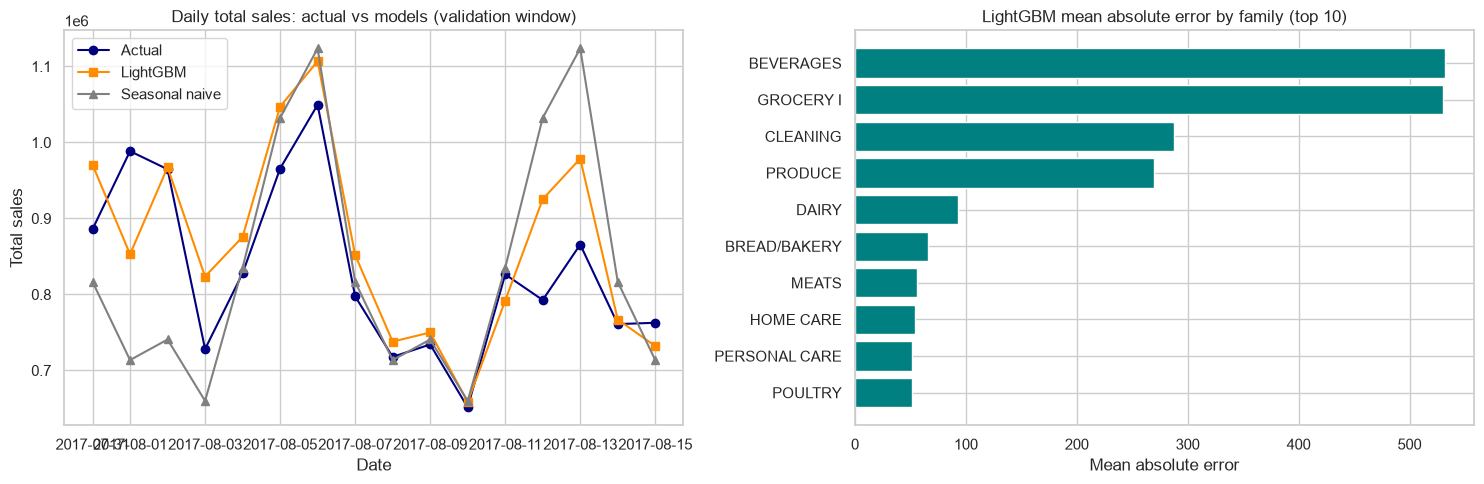

Saved figure to D:\code\retail-sales-forecasting-main\reports\figures\week4_model_comparison.png


In [8]:
if train is not None:
    scored = feature_validation.copy()
    scored["prediction"] = best_predictions

    daily_actual = scored.groupby("date")["sales"].sum()
    daily_pred = scored.groupby("date")["prediction"].sum()
    daily_baseline = merged_baseline.groupby("date")["prediction"].sum()

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    axes[0].plot(daily_actual.index, daily_actual.values, marker="o", label="Actual", color="navy")
    axes[0].plot(daily_pred.index, daily_pred.values, marker="s", label="LightGBM", color="darkorange")
    axes[0].plot(daily_baseline.index, daily_baseline.values, marker="^", label="Seasonal naive", color="gray")
    axes[0].set_title("Daily total sales: actual vs models (validation window)")
    axes[0].set_xlabel("Date")
    axes[0].set_ylabel("Total sales")
    axes[0].legend()

    sample = by_family.head(10).sort_values("mean_abs_error")
    axes[1].barh(sample["family"], sample["mean_abs_error"], color="teal")
    axes[1].set_title("LightGBM mean absolute error by family (top 10)")
    axes[1].set_xlabel("Mean absolute error")

    fig.tight_layout()
    figure_path = FIGURES_DIR / "week4_model_comparison.png"
    fig.savefig(figure_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved figure to {figure_path}")
else:
    print("Skipped: training data is not loaded.")

## 7. Findings

All numbers come from the real 16-day validation window (2017-07-31 to
2017-08-15) on the leakage-safe feature set.

### Models vs baseline
- LightGBM is the strongest candidate by RMSLE, well below the seasonal-naive baseline from Week 3.
- Ridge is a fast linear reference that still beats the baseline, showing the lag and rolling features carry most of the signal.
- Every model is trained on `log1p(sales)` and scored with the same `evaluate_forecast` used for the baseline, so the comparison is apples-to-apples.

### Error structure
- Mean absolute error concentrates in high-volume families (GROCERY I, BEVERAGES, PRODUCE); low-volume families are near zero.
- Residual daily totals track the actual series closely, including the weekly cycle.

### Leakage safeguards
- `lag_7` equals `sales` shifted 7 days within each store/family group and rolling means use past values only, so no validation row sees its own or future sales.

### Baseline to beat
- The Week 3 seasonal-naive RMSLE (~0.617) is the reference; the trained models must and do improve on it.

## Next steps

Week 5 moves to validation strategy and tuning: time-based cross-validation,
hyperparameter search, and possibly holiday/oil signals, with the same
leakage-safe discipline.
